In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv("./data/Cleaned_ships_data.csv")
#print(f"{data.shape} - [строк|колонок]")
#data.head()
#data.dtypes
data.info()
#data.describe()
#data['ship_name'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Company_Name  200 non-null    str  
 1   ship_name     200 non-null    str  
 2   built_year    200 non-null    int64
 3   gt            200 non-null    int64
 4   dwt           200 non-null    int64
 5   length        200 non-null    int64
 6   width         200 non-null    int64
dtypes: int64(5), str(2)
memory usage: 11.1 KB


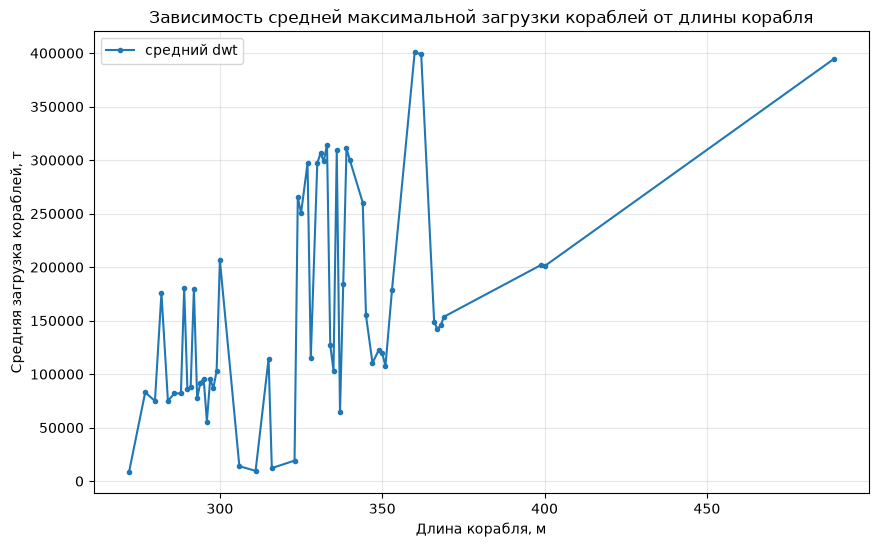

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
series = data.groupby('length')['dwt'].median()
ax.plot(series.index, series.values, label='средний dwt', marker='.')
ax.legend()
ax.set_title("Зависимость средней максимальной загрузки кораблей от длины корабля")
ax.set_ylabel("Средняя загрузка кораблей, т")
ax.set_xlabel("Длина корабля, м")
ax.grid(True, alpha=0.3)

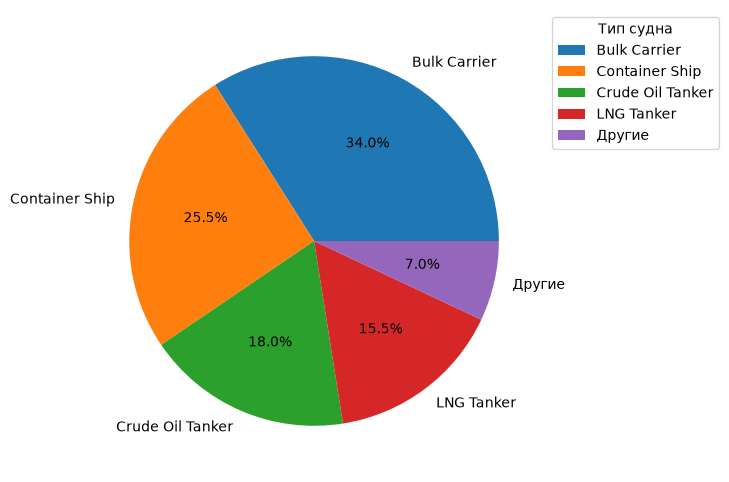

In [26]:
threshold = 10
counts = data['ship_name'].value_counts()
major = counts[counts >threshold].copy()
major['Другие'] = counts[counts <=threshold].sum()

_, ax = plt.subplots(figsize=(10, 6))
ax.pie(major.values, labels=major.index, autopct='%.1f%%')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Тип судна');

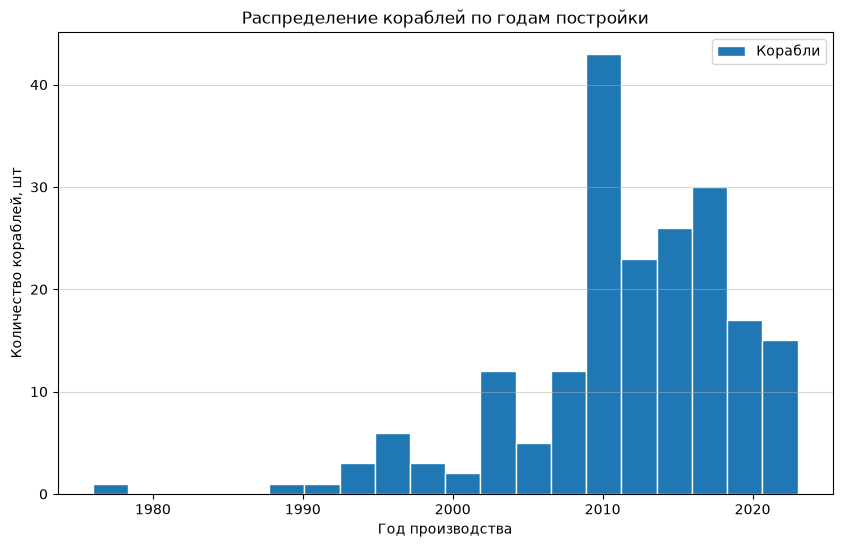

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(data['built_year'], bins=20, edgecolor='white', label='Корабли')
ax.legend()
ax.set_ylabel('Количество кораблей, шт')
ax.set_xlabel('Год производства');
ax.set_title('Распределение кораблей по годам постройки')
ax.grid(True, alpha=0.5, axis='y')

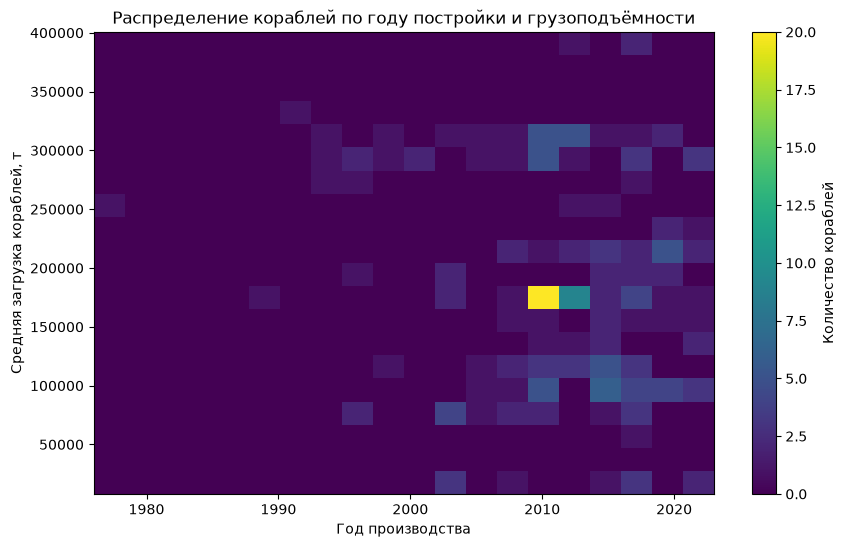

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

h = ax.hist2d(data['built_year'], data['dwt'], bins=[20, 20])
ax.set_xlabel('Год производства')
ax.set_ylabel('Средняя загрузка кораблей, т')
ax.set_title('Распределение кораблей по году постройки и грузоподъёмности')
fig.colorbar(h[3], ax=ax, label='Количество кораблей');